<a href="https://colab.research.google.com/github/RISHABH12005/AIESE/blob/main/Lecture/L20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Software Defect Prediction with Machine Learning

**Goal:** Train and evaluate ML models to predict whether a software module is likely to contain defects.

This notebook uses the public **NASA JM1 software defect dataset** available through OpenML. It is a research-style educational implementation, not a reproduction of any one paper's exact experimental results.

### Learning outcomes
- Load and inspect a real software metrics dataset.
- Prepare features and defect labels.
- Train multiple baseline classifiers.
- Evaluate models using precision, recall, F1-score, ROC-AUC, and a confusion matrix.

**How to use:** Run the cells in order. In Google Colab, choose **Runtime → Run all** to execute the notebook.

## Cell 1 — Install required libraries

This cell installs the Python packages used for data handling, model training, and evaluation. Scikit-learn provides the classifiers and evaluation metrics.

In [1]:
%pip -q install pandas numpy scikit-learn matplotlib

## Cell 2 — Import libraries and load the JM1 dataset

`fetch_openml` downloads the dataset from OpenML. The code keeps features (`X`) and target labels (`y`) separate, which is more robust than assuming the target is always included in the feature table.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml

dataset = fetch_openml(name="jm1", version=1, as_frame=True)

X_raw = dataset.data.copy()
y_raw = pd.Series(dataset.target, name="defects")

print("Feature table shape:", X_raw.shape)
print("Target length:", len(y_raw))
print("Target name:", getattr(dataset, "target_names", None))
print("\nFirst five rows:")
display(X_raw.head())
print("\nTarget values:")
print(y_raw.value_counts(dropna=False))

Feature table shape: (10885, 21)
Target length: 10885
Target name: ['defects']

First five rows:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,t,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,1.30,2,2,2,2,1.2,1.2,1.2,1.2,1.4
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1.00,1,1,1,1,1.0,1.0,1.0,1.0,1.0
2,72.0,7.0,1.0,6.0,198.0,1134.13,0.05,20.31,55.85,23029.10,...,1279.39,51,10,8,1,17.0,36.0,112.0,86.0,13.0
3,190.0,3.0,1.0,3.0,600.0,4348.76,0.06,17.06,254.87,74202.67,...,4122.37,129,29,28,2,17.0,135.0,329.0,271.0,5.0
4,37.0,4.0,1.0,4.0,126.0,599.12,0.06,17.19,34.86,10297.30,...,572.07,28,1,6,0,11.0,16.0,76.0,50.0,7.0



Target values:
defects
false    8779
true     2106
Name: count, dtype: int64


## Cell 3 — Clean labels and prepare numeric features

The target label identifies whether a module is defective. This cell converts common Boolean/string labels to `0` (non-defective) and `1` (defective). It then keeps numeric metrics and converts invalid numeric values to missing values; missing-value imputation is handled inside the model pipeline later.

If the dataset uses unexpected target labels, the cell stops with a helpful message rather than silently guessing.

In [3]:
# Normalize target labels and map common representations to binary labels.
target_text = y_raw.astype(str).str.strip().str.lower()

label_map = {
    "true": 1, "false": 0,
    "yes": 1, "no": 0,
    "1": 1, "0": 0,
    "defective": 1, "non-defective": 0,
    "buggy": 1, "clean": 0
}

y = target_text.map(label_map)

if y.isna().any():
    unknown = sorted(target_text[y.isna()].unique().tolist())
    raise ValueError(
        f"Unexpected target labels: {unknown}. "
        "Inspect y_raw and update label_map for this dataset version."
    )

y = y.astype(int)

# Use numeric software metrics as input features.
X = X_raw.select_dtypes(include=[np.number]).copy()
X = X.replace([np.inf, -np.inf], np.nan)

if X.shape[1] == 0:
    raise ValueError("No numeric features were found in the dataset.")

# Remove rows with missing labels, if any (features can remain missing).
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Prepared feature shape:", X.shape)
print("Number of features:", X.shape[1])
print("\nClass counts (0 = non-defective, 1 = defective):")
print(y.value_counts().sort_index())

Prepared feature shape: (10885, 21)
Number of features: 21

Class counts (0 = non-defective, 1 = defective):
defects
0    8779
1    2106
Name: count, dtype: int64


## Cell 4 — Split the data into training and test sets

The training set is used to learn patterns. The held-out test set is used to estimate performance on unseen examples. `stratify=y` aims to preserve the class proportions in both sets.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 8708
Test rows: 2177


## Cell 5 — Train and compare baseline ML models

The notebook compares Decision Tree, Random Forest, Logistic Regression, and Gaussian Naive Bayes. Imputation is included in each pipeline so missing feature values are handled using training data. Scaling is included for Logistic Regression; tree-based methods do not require feature scaling, but the shared pipeline keeps the example compact.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Gaussian Naive Bayes": GaussianNB()
}

trained_models = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", classifier)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("Training complete for:", ", ".join(trained_models.keys()))

Training complete for: Decision Tree, Random Forest, Logistic Regression, Gaussian Naive Bayes


## Cell 6 — Evaluate model performance

Accuracy alone can be misleading when defective modules are less common than non-defective modules. This cell reports precision, recall, F1-score, and ROC-AUC as well. ROC-AUC is computed from predicted probabilities; it may be undefined if the test split contains only one class.

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

rows = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    try:
        auc = roc_auc_score(y_test, probabilities)
    except ValueError:
        auc = np.nan

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(rows).sort_values("F1-score", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Logistic Regression,0.6977,0.3361,0.5772,0.4248,0.6980
0,Decision Tree,0.7363,0.3423,0.3943,0.3664,0.5874
1,Random Forest,0.8103,0.5204,0.2423,0.3306,0.7251
3,Gaussian Naive Bayes,0.7993,0.4626,0.2352,0.3118,0.6761


## Cell 7 — Inspect the best model with a confusion matrix

The confusion matrix shows true negatives, false positives, false negatives, and true positives. In defect prediction, false negatives are important because they represent defective modules predicted as non-defective.

Best model by test F1-score: Logistic Regression
               precision    recall  f1-score   support

Non-defective       0.88      0.73      0.80      1756
    Defective       0.34      0.58      0.42       421

     accuracy                           0.70      2177
    macro avg       0.61      0.65      0.61      2177
 weighted avg       0.77      0.70      0.72      2177



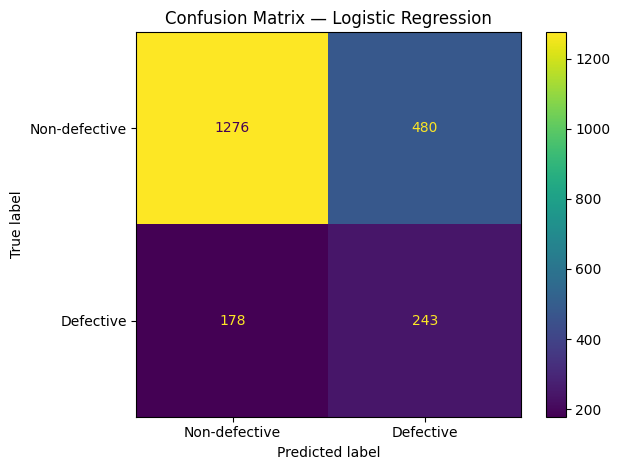

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model by test F1-score:", best_name)
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Non-defective", "Defective"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Non-defective", "Defective"],
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## Cell 8 — Predict defect risk for a new software module

This cell demonstrates how to pass one new module's metrics to the trained model. The example uses the first test row only to demonstrate the prediction interface; in a real workflow, provide metrics for a genuinely new module with exactly the same feature columns.

In [8]:
example_module = X_test.iloc[[0]]
predicted_class = int(best_model.predict(example_module)[0])
predicted_probability = float(best_model.predict_proba(example_module)[0, 1])

print("Predicted class:", "Defective" if predicted_class == 1 else "Non-defective")
print(f"Predicted defect probability: {predicted_probability:.3f}")
print("\nModule features:")
display(example_module)

Predicted class: Non-defective
Predicted defect probability: 0.445

Module features:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,t,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount
936,15.0,3.0,1.0,2.0,46.0,213.62,0.1,10.5,20.34,2242.98,...,124.61,10,0,3,0,15.0,10.0,32.0,14.0,5.0


## Interpretation and limitations

- A prediction is a risk estimate, not proof that a defect exists.
- Results depend on the dataset version, label quality, class imbalance, and train/test split.
- This notebook is an educational baseline. It does not claim to reproduce the exact results of a specific research paper.
- For a research reproduction, follow the paper's precise dataset version, preprocessing, split strategy, model parameters, and evaluation protocol.